# Hoja de Trabajo 6 – Modelación y Simulación (CC2017)

**Grupo 11.** Conjunto $((11-1) \bmod 4)+1 = 3$: $\alpha_{12}=0.6$, $\alpha_{21}=1.5$; $r_1 = 1$, $r_2 = 0.5 + 0.1\,((11-1)\bmod 5) = 0.5$.

Modelo de competencia de Lotka–Volterra:
$$\dot x = r_1 x(1-x-\alpha_{12}y),\qquad \dot y = r_2 y(1-y-\alpha_{21}x)$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import sympy as sp

np.random.seed(11)   # semilla fija: todas las corridas son reproducibles
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Parámetros del grupo: conjunto = ((g-1) mod 4) + 1,  r2 = 0.5 + 0.1((g-1) mod 5)
g = 11
conjunto = ((g - 1) % 4) + 1
ALPHAS = {1: (0.5, 0.6), 2: (1.4, 1.5), 3: (0.6, 1.5), 4: (1.5, 0.6)}
a12, a21 = ALPHAS[conjunto]
r1 = 1.0
r2 = 0.5 + 0.1 * ((g - 1) % 5)
print(f"g = {g} | conjunto = {conjunto} | a12 = {a12}, a21 = {a21} | r1 = {r1}, r2 = {r2}")

# Estados iniciales de referencia
P = {"P1": (0.05, 0.05), "P2": (0.80, 0.30), "P3": (0.30, 0.80), "P4": (0.60, 0.60)}


def make_f(a12=a12, a21=a21, r1=r1, r2=r2):
    """Campo vectorial f(t, z) del modelo:
       x' = r1 x (1 - x - a12 y),   y' = r2 y (1 - y - a21 x).
    z puede ser (2,) o (2, N) para simular N estados iniciales a la vez."""
    def f(t, z):
        x, y = z
        return np.array([r1 * x * (1 - x - a12 * y), r2 * y * (1 - y - a21 * x)])
    return f


def jac(x, y, a12=a12, a21=a21, r1=r1, r2=r2):
    """Matriz jacobiana J = [[r1(1-2x-a12 y), -r1 a12 x], [-r2 a21 y, r2(1-2y-a21 x)]]."""
    return np.array([[r1 * (1 - 2 * x - a12 * y), -r1 * a12 * x],
                     [-r2 * a21 * y, r2 * (1 - 2 * y - a21 * x)]])


f = make_f()

g = 11 | conjunto = 3 | a12 = 0.6, a21 = 1.5 | r1 = 1.0, r2 = 0.5


## Task 1

In [2]:
# Task 1.1 — Equilibrios. SymPy SOLO verifica la derivación hecha a mano.
xs, ys, A12, A21, R1, R2 = sp.symbols("x y alpha12 alpha21 r1 r2")
F = sp.Matrix([R1 * xs * (1 - xs - A12 * ys), R2 * ys * (1 - ys - A21 * xs)])
for s in sp.solve(list(F), [xs, ys], dict=True):
    print("  (x*, y*) =", (sp.simplify(s[xs]), sp.simplify(s[ys])))

# Equilibrio interior derivado a mano: x* = (1-a12)/(1-a12 a21), y* = (1-a21)/(1-a12 a21)
def interior(a12, a21):
    d = 1 - a12 * a21
    return ((1 - a12) / d, (1 - a21) / d)

EQ = {"E0": (0.0, 0.0), "E1": (1.0, 0.0), "E2": (0.0, 1.0), "E3": interior(a12, a21)}
print("\nCon los parámetros del grupo:")
for k, (xe, ye) in EQ.items():
    fact = "factible" if (xe >= 0 and ye >= 0) else "NO factible"
    print(f"  {k} = ({xe:+.4f}, {ye:+.4f})  ->  {fact}")

  (x*, y*) = (0, 0)
  (x*, y*) = (0, 1)
  (x*, y*) = (1, 0)
  (x*, y*) = ((alpha12 - 1)/(alpha12*alpha21 - 1), (alpha21 - 1)/(alpha12*alpha21 - 1))

Con los parámetros del grupo:
  E0 = (+0.0000, +0.0000)  ->  factible
  E1 = (+1.0000, +0.0000)  ->  factible
  E2 = (+0.0000, +1.0000)  ->  factible
  E3 = (+4.0000, -5.0000)  ->  NO factible


In [3]:
# Task 1.2 — Jacobiana (verificación simbólica) y clasificación de cada equilibrio factible
print("J simbólica =", sp.simplify(F.jacobian([xs, ys])))

def clasificar(tau, det):
    """Clasificación por traza y determinante (plano tau-Delta)."""
    disc = tau**2 - 4 * det
    if det < 0:
        return "silla"
    est = "estable" if tau < 0 else "inestable"
    if disc >= 0:
        return f"nodo {est}"
    return "centro" if tau == 0 else f"foco {est}"

factibles = {k: v for k, v in EQ.items() if v[0] >= 0 and v[1] >= 0}
TD = {}
for k, (xe, ye) in factibles.items():
    J = jac(xe, ye)
    tau, det = np.trace(J), np.linalg.det(J)
    lam, V = np.linalg.eig(J)
    lam, V = np.real_if_close(lam), np.real_if_close(V)   # valores propios reales
    TD[k] = (tau, det)
    print(f"\n{k} = ({xe:g}, {ye:g})   J = {(J.round(4) + 0.0).tolist()}")
    print(f"   tau = {tau:+.4f}  Delta = {det:+.4f}  tau^2-4Delta = {tau**2 - 4*det:+.4f}")
    print(f"   lambda = {np.round(lam, 4)}  ->  {clasificar(tau, det)}")
    for i in range(2):
        print(f"   v(lambda={lam[i]:+.2f}) = {np.round(V[:, i] / np.max(np.abs(V[:, i])), 4)}")

# Solo como referencia: el equilibrio interior (no factible) también es una silla
xe, ye = EQ["E3"]
print(f"\nE3 (no factible): Delta = {np.linalg.det(jac(xe, ye)):+.4f}")

J simbólica = Matrix([[r1*(-alpha12*y - 2*x + 1), -alpha12*r1*x], [-alpha21*r2*y, r2*(-alpha21*x - 2*y + 1)]])

E0 = (0, 0)   J = [[1.0, 0.0], [0.0, 0.5]]
   tau = +1.5000  Delta = +0.5000  tau^2-4Delta = +0.2500
   lambda = [1.  0.5]  ->  nodo inestable
   v(lambda=+1.00) = [1. 0.]
   v(lambda=+0.50) = [0. 1.]

E1 = (1, 0)   J = [[-1.0, -0.6], [0.0, -0.25]]
   tau = -1.2500  Delta = +0.2500  tau^2-4Delta = +0.5625
   lambda = [-1.   -0.25]  ->  nodo estable
   v(lambda=-1.00) = [1. 0.]
   v(lambda=-0.25) = [-0.8  1. ]

E2 = (0, 1)   J = [[0.4, 0.0], [-0.75, -0.5]]
   tau = -0.1000  Delta = -0.2000  tau^2-4Delta = +0.8100
   lambda = [-0.5  0.4]  ->  silla
   v(lambda=-0.50) = [0. 1.]
   v(lambda=+0.40) = [ 1.     -0.8333]

E3 (no factible): Delta = -1.0000


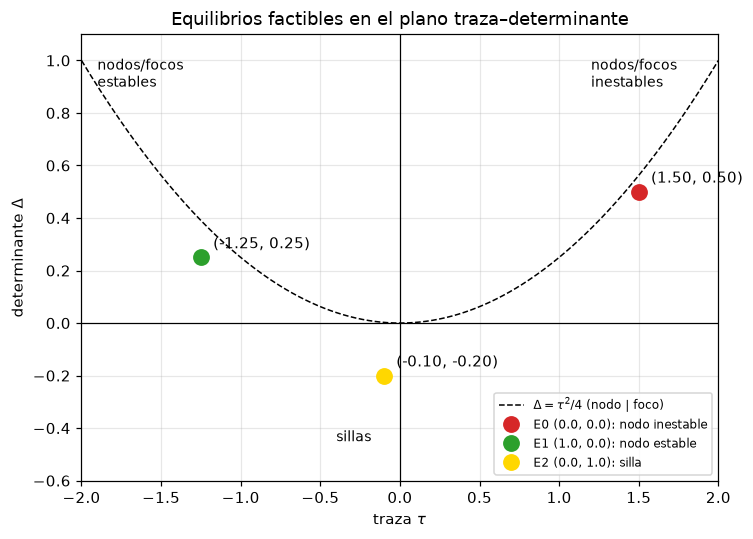

In [4]:
# Task 1.2c — Ubicación de los equilibrios en el plano traza-determinante
fig, ax = plt.subplots(figsize=(7, 5))
tt = np.linspace(-2, 2, 400)
ax.plot(tt, tt**2 / 4, "k--", lw=1, label=r"$\Delta = \tau^2/4$ (nodo | foco)")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(0, color="k", lw=0.8)
colores = {"E0": "tab:red", "E1": "tab:green", "E2": "gold"}
for k, (tau, det) in TD.items():
    ax.plot(tau, det, "o", ms=10, color=colores[k],
            label=f"{k} {factibles[k]}: {clasificar(tau, det)}")
    ax.annotate(f"({tau:.2f}, {det:.2f})", (tau, det), textcoords="offset points", xytext=(8, 6))
ax.text(-1.9, 0.9, "nodos/focos\nestables", fontsize=9)
ax.text(1.2, 0.9, "nodos/focos\ninestables", fontsize=9)
ax.text(-0.4, -0.45, "sillas", fontsize=9)
ax.set(xlim=(-2, 2), ylim=(-0.6, 1.1), xlabel=r"traza $\tau$", ylabel=r"determinante $\Delta$",
       title="Equilibrios factibles en el plano traza–determinante")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

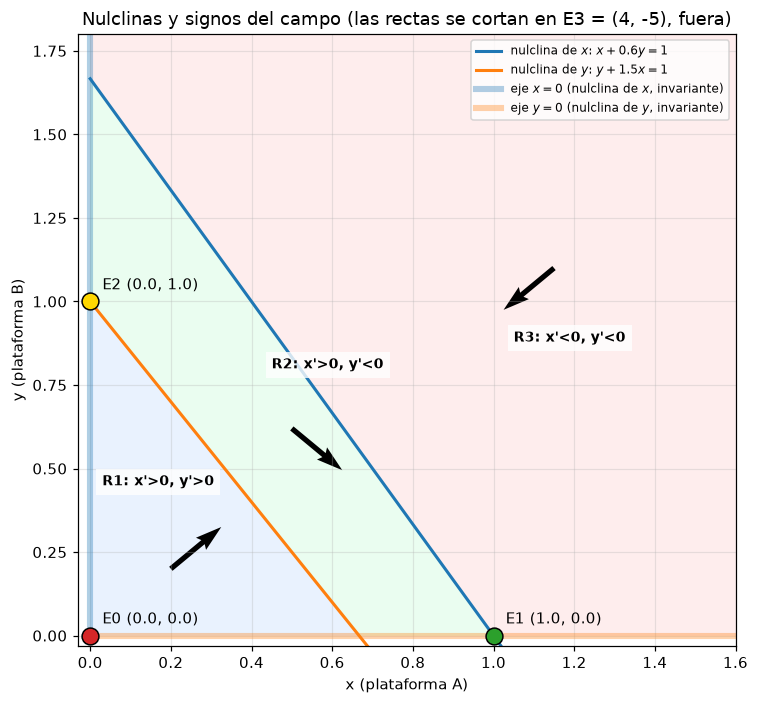

P1 = (0.05, 0.05): x + a12 y = 0.08, y + a21 x = 0.12 -> R1
P2 = (0.8, 0.3): x + a12 y = 0.98, y + a21 x = 1.50 -> R2
P3 = (0.3, 0.8): x + a12 y = 0.78, y + a21 x = 1.25 -> R2
P4 = (0.6, 0.6): x + a12 y = 0.96, y + a21 x = 1.50 -> R2


In [5]:
# Task 1.3a-b — Nulclinas, regiones y dirección del campo en cada región
# Nulclinas de x: x = 0  y  x + a12 y = 1  ->  y = (1 - x)/a12
# Nulclinas de y: y = 0  y  y + a21 x = 1  ->  y = 1 - a21 x
fig, ax = plt.subplots(figsize=(7, 6.5))
x = np.linspace(0, 1.6, 400)
ax.plot(x, (1 - x) / a12, color="tab:blue", lw=2, label=r"nulclina de $x$: $x + 0.6y = 1$")
ax.plot(x, 1 - a21 * x, color="tab:orange", lw=2, label=r"nulclina de $y$: $y + 1.5x = 1$")
ax.plot([0, 0], [0, 1.8], color="tab:blue", lw=4, alpha=0.35, label=r"eje $x=0$ (nulclina de $x$, invariante)")
ax.plot([0, 1.6], [0, 0], color="tab:orange", lw=4, alpha=0.35, label=r"eje $y=0$ (nulclina de $y$, invariante)")

# Regiones: R1 debajo de ambas rectas, R2 entre ellas, R3 encima de ambas
X, Y = np.meshgrid(np.linspace(0, 1.6, 300), np.linspace(0, 1.8, 300))
region = np.where(Y + a21 * X < 1, 1, np.where(X + a12 * Y < 1, 2, 3))
ax.contourf(X, Y, region, levels=[0.5, 1.5, 2.5, 3.5],
            colors=["#dbeafe", "#dcfce7", "#fee2e2"], alpha=0.6)

# Una flecha de signos (sgn x', sgn y') en un punto representativo de cada región
rep = {"R1": ((0.2, 0.2), (0.03, 0.45)), "R2": ((0.5, 0.62), (0.45, 0.80)),
       "R3": ((1.15, 1.1), (1.05, 0.88))}
for nombre, ((px, py), (tx, ty)) in rep.items():
    u, v = np.sign(f(0, np.array([px, py])))
    ax.quiver(px, py, u, v, angles="xy", scale_units="xy", scale=8, width=0.008)
    ax.text(tx, ty, f"{nombre}: x'{'>' if u > 0 else '<'}0, y'{'>' if v > 0 else '<'}0",
            fontsize=9, weight="bold", bbox=dict(fc="white", ec="none", alpha=0.8))

# Intersecciones de nulclinas (equilibrios) dentro del cuadrante
for k, c in [("E0", "tab:red"), ("E1", "tab:green"), ("E2", "gold")]:
    ax.plot(*EQ[k], "o", ms=11, color=c, mec="k", zorder=5)
    ax.annotate(f"{k} {EQ[k]}", EQ[k], textcoords="offset points", xytext=(8, 8))
ax.set(xlim=(-0.03, 1.6), ylim=(-0.03, 1.8), xlabel="x (plataforma A)", ylabel="y (plataforma B)",
       title="Nulclinas y signos del campo (las rectas se cortan en E3 = (4, -5), fuera)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

for k, (px, py) in P.items():
    zona = "R1" if py + a21 * px < 1 else ("R2" if px + a12 * py < 1 else "R3")
    print(f"{k} = {(px, py)}: x + a12 y = {px + a12*py:.2f}, y + a21 x = {py + a21*px:.2f} -> {zona}")

In [6]:
# Task 1.3d — Tiempo característico de recuperación: T_rec = 1 / min|Re(lambda)|
lam = np.real_if_close(np.linalg.eigvals(jac(*EQ["E1"])))
print("lambda en E1 =", lam, "->  T_rec =", 1 / np.min(np.abs(lam.real)))

lambda en E1 = [-1.   -0.25] ->  T_rec = 4.0


In [7]:
# Task 1.4 — Revisión del análisis del compañero (a12 = 1.4, a21 = 1.5, r1 = 1, r2 = 0.8)
pc = dict(a12=1.4, a21=1.5, r1=1.0, r2=0.8)
xc, yc = interior(pc["a12"], pc["a21"])
Jc = jac(xc, yc, **pc)
tau = np.trace(Jc)
det_mal = Jc[0, 0] * Jc[1, 1] + Jc[0, 1] * Jc[1, 0]     # fórmula del compañero (signo +)
det_bien = Jc[0, 0] * Jc[1, 1] - Jc[0, 1] * Jc[1, 0]    # determinante correcto
print(f"(x*, y*) = ({xc:.4f}, {yc:.4f})")
print("J =", Jc.round(4).tolist())
print(f"tau = {tau:.4f}")
print(f"Delta (compañero, J11J22 + J12J21) = {det_mal:+.4f}")
print(f"Delta (correcto,  J11J22 - J12J21) = {det_bien:+.4f}  = np.linalg.det: {np.linalg.det(Jc):+.4f}")
lam_c = np.real_if_close(np.linalg.eigvals(Jc))
print("lambda =", lam_c.round(4), "->", clasificar(tau, det_bien))
for k in ["E1", "E2"]:
    print(f"{k}: lambda = {np.real_if_close(np.linalg.eigvals(jac(*EQ[k], **pc))).round(4)}")

(x*, y*) = (0.3636, 0.4545)
J = [[-0.3636, -0.5091], [-0.5455, -0.3636]]
tau = -0.7273
Delta (compañero, J11J22 + J12J21) = +0.4099
Delta (correcto,  J11J22 - J12J21) = -0.1455  = np.linalg.det: -0.1455
lambda = [ 0.1633 -0.8906] -> silla
E1: lambda = [-1.  -0.4]
E2: lambda = [-0.8 -0.4]


## Task 2

In [8]:
# Task 2.1a — Integradores implementados desde cero (sin solve_ivp)
def euler_step(f, t, z, h):
    """Euler explícito: z_{n+1} = z_n + h f(t_n, z_n)   (orden 1)."""
    return z + h * f(t, z)


def rk4_step(f, t, z, h):
    """Runge-Kutta clásico de orden 4:
       k1 = f(t, z)
       k2 = f(t + h/2, z + h k1/2)
       k3 = f(t + h/2, z + h k2/2)
       k4 = f(t + h,   z + h k3)
       z_{n+1} = z_n + h (k1 + 2 k2 + 2 k3 + k4) / 6"""
    k1 = f(t, z)
    k2 = f(t + h / 2, z + h * k1 / 2)
    k3 = f(t + h / 2, z + h * k2 / 2)
    k4 = f(t + h, z + h * k3)
    return z + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6


def integrar(step, f, z0, h, T):
    """Aplica 'step' N = T/h veces desde z0. Devuelve los tiempos y la trayectoria."""
    n = int(round(T / h))
    t = np.arange(n + 1) * h
    Z = np.empty((n + 1, len(z0)))
    Z[0] = z0
    for k in range(n):
        Z[k + 1] = step(f, t[k], Z[k], h)
    return t, Z


def euler(f, z0, h, T):
    return integrar(euler_step, f, np.asarray(z0, float), h, T)


def rk4(f, z0, h, T):
    return integrar(rk4_step, f, np.asarray(z0, float), h, T)

In [9]:
# Task 2.1b — Error global en T = 10 desde P2 contra solve_ivp (DOP853, tol = 1e-12)
T = 10.0
z0 = np.array(P["P2"])
ref = solve_ivp(f, (0, T), z0, method="DOP853", rtol=1e-12, atol=1e-12)
z_ref = ref.y[:, -1]
print("Referencia z(10) =", z_ref)

hs = np.array([0.2, 0.1, 0.05, 0.025, 0.0125])
# Error = norma euclidiana de la diferencia en el tiempo final: ||z_h(T) - z_ref(T)||
err_eu = np.array([np.linalg.norm(euler(f, z0, h, T)[1][-1] - z_ref) for h in hs])
err_rk = np.array([np.linalg.norm(rk4(f, z0, h, T)[1][-1] - z_ref) for h in hs])
print(f"\n{'h':>8} {'error Euler':>14} {'razón':>7} {'error RK4':>14} {'razón':>7}")
for i, h in enumerate(hs):
    re = err_eu[i - 1] / err_eu[i] if i else np.nan
    rr = err_rk[i - 1] / err_rk[i] if i else np.nan
    print(f"{h:8.4f} {err_eu[i]:14.3e} {re:7.2f} {err_rk[i]:14.3e} {rr:7.2f}")

Referencia z(10) = [0.97824905 0.02704421]

       h    error Euler   razón      error RK4   razón
  0.2000      1.987e-03     nan      4.044e-09     nan
  0.1000      9.919e-04    2.00      2.477e-10   16.33
  0.0500      4.955e-04    2.00      1.527e-11   16.22
  0.0250      2.477e-04    2.00      8.960e-13   17.04
  0.0125      1.238e-04    2.00      7.556e-14   11.86


Pendiente Euler = 1.0010  (teórico 1)
Pendiente RK4   = 3.9526  (teórico 4)
Pendiente RK4 sin h = 0.0125 = 4.0440


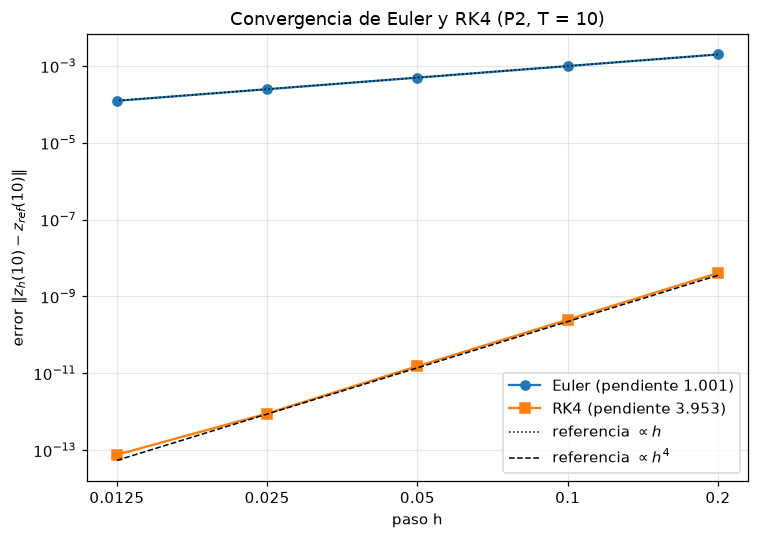

In [10]:
# Task 2.1c — Log-log del error vs h y pendiente por regresión lineal de log(error) = p log(h) + c
p_eu, c_eu = np.polyfit(np.log(hs), np.log(err_eu), 1)
p_rk, c_rk = np.polyfit(np.log(hs), np.log(err_rk), 1)
print(f"Pendiente Euler = {p_eu:.4f}  (teórico 1)")
print(f"Pendiente RK4   = {p_rk:.4f}  (teórico 4)")
p_rk4 = np.polyfit(np.log(hs[:-1]), np.log(err_rk[:-1]), 1)[0]
print(f"Pendiente RK4 sin h = 0.0125 = {p_rk4:.4f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(hs, err_eu, "o-", label=f"Euler (pendiente {p_eu:.3f})")
ax.loglog(hs, err_rk, "s-", label=f"RK4 (pendiente {p_rk:.3f})")
ax.loglog(hs, np.exp(c_eu) * hs**1, "k:", lw=1, label=r"referencia $\propto h$")
ax.loglog(hs, np.exp(c_rk) * hs**4, "k--", lw=1, label=r"referencia $\propto h^4$")
ax.set_xticks(hs, [f"{h:g}" for h in hs])
ax.minorticks_off()
ax.set(xlabel="paso h", ylabel=r"error $\|z_h(10) - z_{ref}(10)\|$",
       title="Convergencia de Euler y RK4 (P2, T = 10)")
ax.legend()
plt.tight_layout()
plt.show()

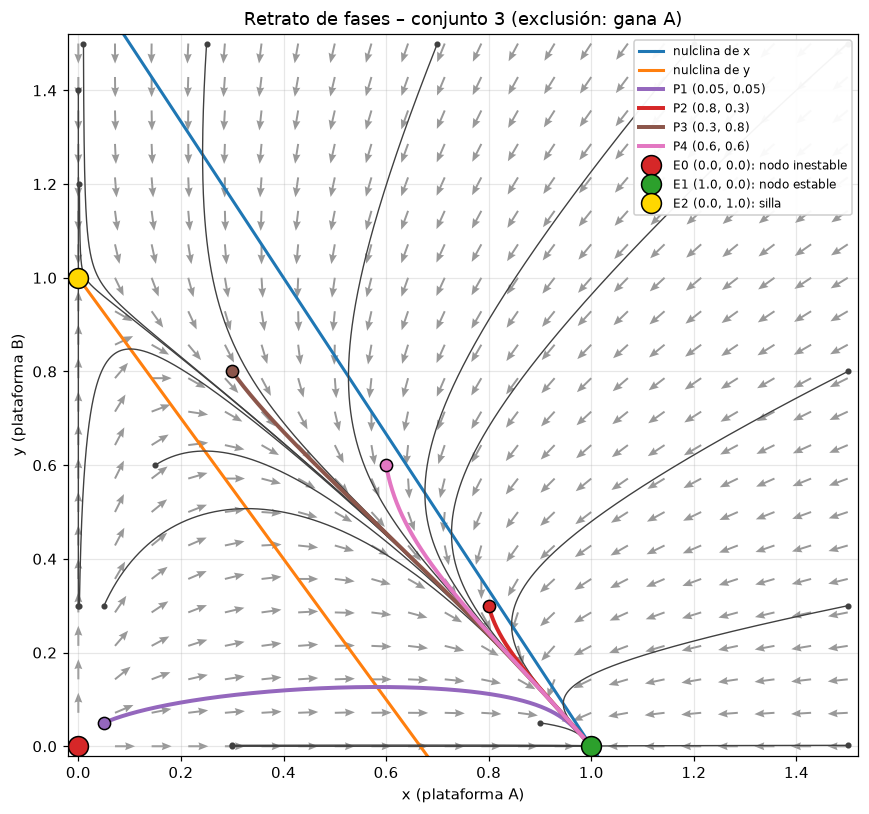

In [11]:
# Task 2.2a-b — Retrato de fases en [0, 1.5]^2 con trayectorias RK4 (h = 0.01, T = 80)
h_pp, T_pp = 0.01, 80.0
fig, ax = plt.subplots(figsize=(8, 7.5))

# Campo vectorial con flechas normalizadas (solo dirección)
Xq, Yq = np.meshgrid(np.linspace(0, 1.5, 22), np.linspace(0, 1.5, 22))
U, V = f(0, np.array([Xq, Yq]))
N = np.hypot(U, V)
N[N == 0] = 1
ax.quiver(Xq, Yq, U / N, V / N, color="0.6", angles="xy", width=0.0025, headwidth=4)

# Nulclinas
xx = np.linspace(0, 1.5, 300)
ax.plot(xx, (1 - xx) / a12, color="tab:blue", lw=2, label="nulclina de x")
ax.plot(xx, 1 - a21 * xx, color="tab:orange", lw=2, label="nulclina de y")

# Al menos 12 trayectorias: bordes del cuadro, muy cerca de los ejes y sobre los ejes
inits = [(0.002, 0.3), (0.002, 1.2), (0.01, 1.5), (0.3, 0.002), (1.5, 0.002),
         (0.25, 1.5), (0.7, 1.5), (1.2, 1.5), (1.5, 1.5), (1.5, 0.8), (1.5, 0.3),
         (0.15, 0.6), (0.05, 0.3), (0.9, 0.05), (0.0, 0.3), (0.0, 1.4), (0.3, 0.0)]
for z0_ in inits:
    _, Z = rk4(f, z0_, h_pp, T_pp)
    ax.plot(Z[:, 0], Z[:, 1], color="0.25", lw=0.9)
    ax.plot(*z0_, ".", color="0.25")

# Trayectorias de P1-P4 resaltadas
colP = {"P1": "tab:purple", "P2": "tab:red", "P3": "tab:brown", "P4": "tab:pink"}
fin = {}
for k, z0_ in P.items():
    t_, Z = rk4(f, z0_, h_pp, T_pp)
    fin[k] = (t_, Z)
    ax.plot(Z[:, 0], Z[:, 1], color=colP[k], lw=2.6, label=f"{k} {z0_}")
    ax.plot(*z0_, "o", ms=8, color=colP[k], mec="k")

# Equilibrios coloreados por tipo
estilo = {"E0": ("tab:red", "nodo inestable"), "E1": ("tab:green", "nodo estable"),
          "E2": ("gold", "silla")}
for k, (c, tipo) in estilo.items():
    ax.plot(*EQ[k], "o", ms=13, color=c, mec="k", zorder=6, label=f"{k} {EQ[k]}: {tipo}")
ax.set(xlim=(-0.02, 1.52), ylim=(-0.02, 1.52), xlabel="x (plataforma A)", ylabel="y (plataforma B)",
       title="Retrato de fases – conjunto 3 (exclusión: gana A)")
ax.legend(loc="upper right", fontsize=8, framealpha=0.95)
plt.tight_layout()
plt.show()

In [12]:
# Task 2.2c — ¿A qué equilibrio llega cada estado de referencia? (RK4, h = 0.01, T = 80)
for k, (t_, Z) in fin.items():
    d = np.linalg.norm(Z - np.array(EQ["E1"]), axis=1)
    t_llega = t_[np.argmax(d < 1e-3)]
    print(f"{k} {P[k]} -> z(80) = ({Z[-1, 0]:.6f}, {Z[-1, 1]:.2e}) ~ E1 (1, 0);"
          f" |z - E1| < 1e-3 desde t = {t_llega:.2f};  y_max = {Z[:, 1].max():.3f}")

P1 (0.05, 0.05) -> z(80) = (1.000000, 9.27e-10) ~ E1 (1, 0); |z - E1| < 1e-3 desde t = 25.43;  y_max = 0.127
P2 (0.8, 0.3) -> z(80) = (1.000000, 6.87e-10) ~ E1 (1, 0); |z - E1| < 1e-3 desde t = 24.23;  y_max = 0.300
P3 (0.3, 0.8) -> z(80) = (1.000000, 3.25e-09) ~ E1 (1, 0); |z - E1| < 1e-3 desde t = 30.44;  y_max = 0.800
P4 (0.6, 0.6) -> z(80) = (1.000000, 1.59e-09) ~ E1 (1, 0); |z - E1| < 1e-3 desde t = 27.58;  y_max = 0.600


Equilibrios estables: ['E1']


Sin converger tras T = 1000.0: 0 de 3600
Tiempo de convergencia: mín = 36.65, máx = 68.70


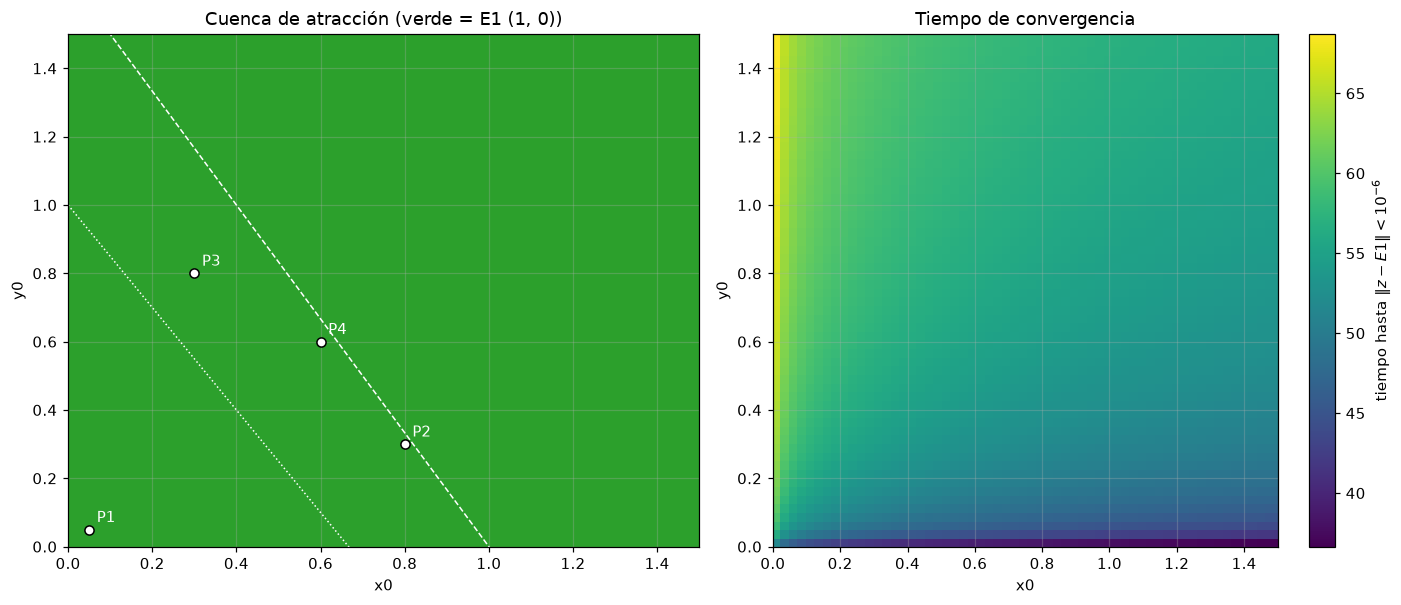

Fracción en la cuenca de E1 (1.0, 0.0): 1.0000


In [13]:
# Task 2.3a — Mapa de cuencas: malla 60x60 en [0.01, 1.5]^2, RK4 vectorizado (h = 0.05)
n = 60
g1 = np.linspace(0.01, 1.5, n)
Xg, Yg = np.meshgrid(g1, g1)
Z = np.vstack([Xg.ravel(), Yg.ravel()])           # 3600 estados iniciales a la vez

# Equilibrios estables (atractores) del régimen: todos los Re(lambda) < 0
estables = [k for k in factibles if np.all(np.linalg.eigvals(jac(*EQ[k])).real < 0)]
Zs = np.array([EQ[k] for k in estables]).T          # (2, n_estables)
print("Equilibrios estables:", estables)

# Criterio: un estado converge cuando ||z - z*|| < tol para un equilibrio ESTABLE z*
tol, h_b, Tmax = 1e-6, 0.05, 1000.0
etiqueta = np.full(Z.shape[1], -1)
t_conv = np.full(Z.shape[1], np.nan)
activos = np.ones(Z.shape[1], bool)
t = 0.0
while activos.any() and t < Tmax:
    Z[:, activos] = rk4_step(f, t, Z[:, activos], h_b)
    t += h_b
    dist = np.linalg.norm(Z[:, activos, None] - Zs[:, None, :], axis=0)   # (activos, n_estables)
    llego = dist.min(axis=1) < tol
    idx = np.flatnonzero(activos)[llego]
    etiqueta[idx] = dist[llego].argmin(axis=1)
    t_conv[idx] = t
    activos[idx] = False
print(f"Sin converger tras T = {Tmax}: {activos.sum()} de {Z.shape[1]}")
print(f"Tiempo de convergencia: mín = {np.nanmin(t_conv):.2f}, máx = {np.nanmax(t_conv):.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.6))
cmap = plt.matplotlib.colors.ListedColormap(["tab:green", "tab:orange"][:len(estables)])
a1.pcolormesh(Xg, Yg, etiqueta.reshape(n, n), cmap=cmap, shading="nearest")
a1.plot(xx, (1 - xx) / a12, "w--", lw=1)
a1.plot(xx, 1 - a21 * xx, "w:", lw=1)
for k in P:
    a1.plot(*P[k], "o", color="w", mec="k")
    a1.annotate(k, P[k], textcoords="offset points", xytext=(5, 5), color="w")
a1.set(xlim=(0, 1.5), ylim=(0, 1.5), xlabel="x0", ylabel="y0",
       title=f"Cuenca de atracción (verde = {estables[0]} (1, 0))")
im = a2.pcolormesh(Xg, Yg, t_conv.reshape(n, n), cmap="viridis", shading="nearest")
fig.colorbar(im, ax=a2, label=r"tiempo hasta $\|z - E1\| < 10^{-6}$")
a2.set(xlim=(0, 1.5), ylim=(0, 1.5), xlabel="x0", ylabel="y0", title="Tiempo de convergencia")
plt.tight_layout()
plt.show()

# Task 2.3b — Fracción del cuadrante en cada cuenca
for i, k in enumerate(estables):
    print(f"Fracción en la cuenca de {k} {EQ[k]}: {np.mean(etiqueta == i):.4f}")

In [14]:
# Task 2.3d — Por qué la cuenca es todo el cuadrante: escape desde la silla E2 cerca del eje x = 0
# Cerca de E2 = (0, 1), x crece como x(t) ~ x0 exp(lambda_u t) con lambda_u = r1 (1 - a12) = 0.4
lam_u = r1 * (1 - a12)
col = n // 2   # columna y0 = g1[30]
for i in [0, 1, 3, 10, 30]:
    k_ = col * n + i      # fila y0 fija, varía x0
    print(f"x0 = {Xg.ravel()[k_]:.3f}, y0 = {Yg.ravel()[k_]:.3f}: t_conv = {t_conv[k_]:6.2f}")
print(f"Pendiente teórica dt/d(ln x0) cerca del eje: -1/lambda_u = {-1/lam_u:.2f}")
x0s = Xg.ravel()[col * n:col * n + 6]
tc = t_conv[col * n:col * n + 6]
print(f"Pendiente medida (primeras 6 columnas): {np.polyfit(np.log(x0s), tc, 1)[0]:.2f}")
_, Zax = rk4(f, (0.0, 0.5), 0.05, 200)
print("Sobre el eje x0 = 0 exacto: (0, 0.5) ->", Zax[-1].round(6), "(llega a la silla E2)")

x0 = 0.010, y0 = 0.768: t_conv =  66.65
x0 = 0.035, y0 = 0.768: t_conv =  63.50
x0 = 0.086, y0 = 0.768: t_conv =  61.20
x0 = 0.263, y0 = 0.768: t_conv =  58.30
x0 = 0.768, y0 = 0.768: t_conv =  55.45
Pendiente teórica dt/d(ln x0) cerca del eje: -1/lambda_u = -2.50
Pendiente medida (primeras 6 columnas): -2.54
Sobre el eje x0 = 0 exacto: (0, 0.5) -> [0. 1.] (llega a la silla E2)


lambda(E1) = [-1.   -0.25]  v_lento = [-0.6247  0.7809]


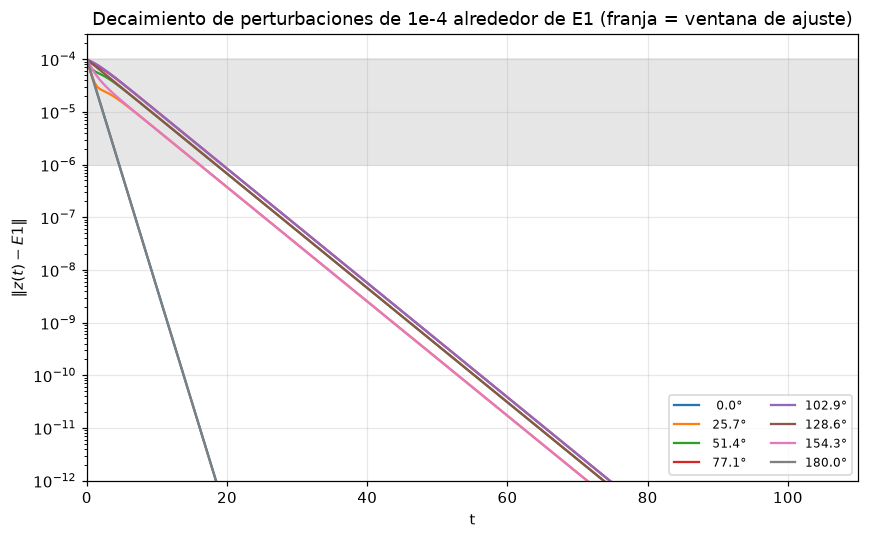

  theta  tasa ini  tasa 1e-4→1e-6  tasa 1e-8→1e-10  max|e|/1e-4   ventana [t0, t1]
    0.0    1.0001          1.0000           1.0000        1.000    [ 0.00,   4.61]
   25.7    1.0532          0.2456           0.2500        1.000    [ 0.00,  16.07]
   51.4    0.6577          0.2415           0.2500        1.000    [ 0.00,  18.43]
   77.1    0.2889          0.2428           0.2500        1.000    [ 0.00,  19.31]
  102.9    0.1467          0.2453           0.2500        1.000    [ 0.00,  19.31]
  128.6    0.2492          0.2500           0.2500        1.000    [ 0.00,  18.43]
  154.3    0.5813          0.2660           0.2500        1.000    [ 0.00,  16.08]
  180.0    0.9999          1.0000           1.0000        1.000    [ 0.00,   4.61]


In [15]:
# Task 2.4a — Perturbaciones de 1e-4 en 8 direcciones alrededor de E1 = (1, 0)
zs = np.array(EQ["E1"])
lam1, V1 = np.linalg.eig(jac(*zs))
lam1, V1 = np.real_if_close(lam1), np.real_if_close(V1)
print("lambda(E1) =", lam1, " v_lento =", (V1[:, 1] / np.linalg.norm(V1[:, 1])).round(4))
# Como E1 está sobre el eje y = 0, solo se permite y >= 0: semiplano superior.
# 8 direcciones igualmente espaciadas entre 0 y 180 grados (ambos ejes incluidos).
thetas = np.linspace(0, np.pi, 8)
h_p, T_p = 0.01, 110.0
tasas = []
fig, ax = plt.subplots(figsize=(8, 5))
for th in thetas:
    z0_ = zs + 1e-4 * np.array([np.cos(th), np.sin(th)])
    t_, Z = rk4(f, z0_, h_p, T_p)
    d = np.linalg.norm(Z - zs, axis=1)
    # Ventana: desde la última vez que ||e|| >= 1e-4 hasta la primera vez que ||e|| <= 1e-6
    i0 = np.flatnonzero(d >= 1e-4 * (1 - 1e-9)).max()   # tolerancia por redondeo en d[0]
    i1 = np.argmax(d <= 1e-6)
    s_win = -np.polyfit(t_[i0:i1 + 1], np.log(d[i0:i1 + 1]), 1)[0]
    s_ini = -np.polyfit(t_[:51], np.log(d[:51]), 1)[0]             # primeros 0.5 u.t.
    j0, j1 = np.argmax(d <= 1e-8), np.argmax(d <= 1e-10)
    s_tail = -np.polyfit(t_[j0:j1 + 1], np.log(d[j0:j1 + 1]), 1)[0] if j1 > j0 else np.nan
    tasas.append((np.degrees(th), s_ini, s_win, s_tail, d.max() / 1e-4, t_[i0], t_[i1]))
    ax.semilogy(t_, d, label=f"{np.degrees(th):5.1f}°")
ax.axhspan(1e-6, 1e-4, color="0.9", zorder=0)
ax.set(xlabel="t", ylabel=r"$\|z(t) - E1\|$", ylim=(1e-12, 3e-4), xlim=(0, 110),
       title="Decaimiento de perturbaciones de 1e-4 alrededor de E1 (franja = ventana de ajuste)")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

print(f"{'theta':>7} {'tasa ini':>9} {'tasa 1e-4→1e-6':>15} {'tasa 1e-8→1e-10':>16} "
      f"{'max|e|/1e-4':>12} {'ventana [t0, t1]':>18}")
for th, si, sw, st, amp, ta, tb in tasas:
    print(f"{th:7.1f} {si:9.4f} {sw:15.4f} {st:16.4f} {amp:12.3f}    [{ta:5.2f}, {tb:6.2f}]")

In [16]:
# Task 2.4b — Comparación con min|Re(lambda)| = 0.25 (Task 1.2)
s_teo = np.min(np.abs(lam1.real))
print(f"min|Re(lambda)| = {s_teo}")
for th, si, sw, st, *_ in tasas:
    print(f"theta = {th:6.1f}°: tasa ventana = {sw:.4f}  error relativo = {abs(sw - s_teo)/s_teo:7.2%}"
          f" | tasa final = {st:.4f}  error relativo = {abs(st - s_teo)/s_teo:7.2%}")

min|Re(lambda)| = 0.25
theta =    0.0°: tasa ventana = 1.0000  error relativo = 300.01% | tasa final = 1.0000  error relativo = 300.00%
theta =   25.7°: tasa ventana = 0.2456  error relativo =   1.76% | tasa final = 0.2500  error relativo =   0.00%
theta =   51.4°: tasa ventana = 0.2415  error relativo =   3.39% | tasa final = 0.2500  error relativo =   0.00%
theta =   77.1°: tasa ventana = 0.2428  error relativo =   2.86% | tasa final = 0.2500  error relativo =   0.00%
theta =  102.9°: tasa ventana = 0.2453  error relativo =   1.89% | tasa final = 0.2500  error relativo =   0.00%
theta =  128.6°: tasa ventana = 0.2500  error relativo =   0.01% | tasa final = 0.2500  error relativo =   0.00%
theta =  154.3°: tasa ventana = 0.2660  error relativo =   6.40% | tasa final = 0.2500  error relativo =   0.00%
theta =  180.0°: tasa ventana = 1.0000  error relativo = 299.99% | tasa final = 1.0000  error relativo = 300.00%


In [17]:
# Task 2.4c — Estabilidad lineal de Euler: |1 + h lambda| < 1  <=>  h < 2|Re(lambda)| / |lambda|^2
for l in lam1:
    print(f"lambda = {l:+.2f}:  h_max = 2|Re(lambda)|/|lambda|^2 = {2*abs(l.real)/abs(l)**2:.3f}")
h_teo = min(2 * abs(l.real) / abs(l)**2 for l in lam1)
print("h_max (más restrictivo) =", h_teo)

lambda = -1.00:  h_max = 2|Re(lambda)|/|lambda|^2 = 2.000
lambda = -0.25:  h_max = 2|Re(lambda)|/|lambda|^2 = 8.000
h_max (más restrictivo) = 2.0


Desde E1 + 1e-4(cos45°, sin45°): h_max numérico = 1.999953   (teórico 2.0)
Error relativo = 2.36e-05


Desde P1 (0.05, 0.05): h_max numérico = 1.999936


Desde P2 (0.8, 0.3): h_max numérico = 1.999936


Desde P3 (0.3, 0.8): h_max numérico = 1.999939


Desde P4 (0.6, 0.6): h_max numérico = 1.999936
h = 1.5: últimos x_n = [1. 1. 1. 1.], y_n final = 2.3e-29
h = 1.95: últimos x_n = [1. 1. 1. 1.], y_n final = 1.0e-39
h = 2.05: últimos x_n = [0.96227 1.0367  0.95871 1.03986], y_n final = 2.6e-42
h = 2.3: últimos x_n = [0.68787 1.18169 0.68787 1.18169], y_n final = 1.1e-59
h = 2.6: últimos x_n = [0.82818 1.19815 0.58086 1.21386], y_n final = 3.5e-72


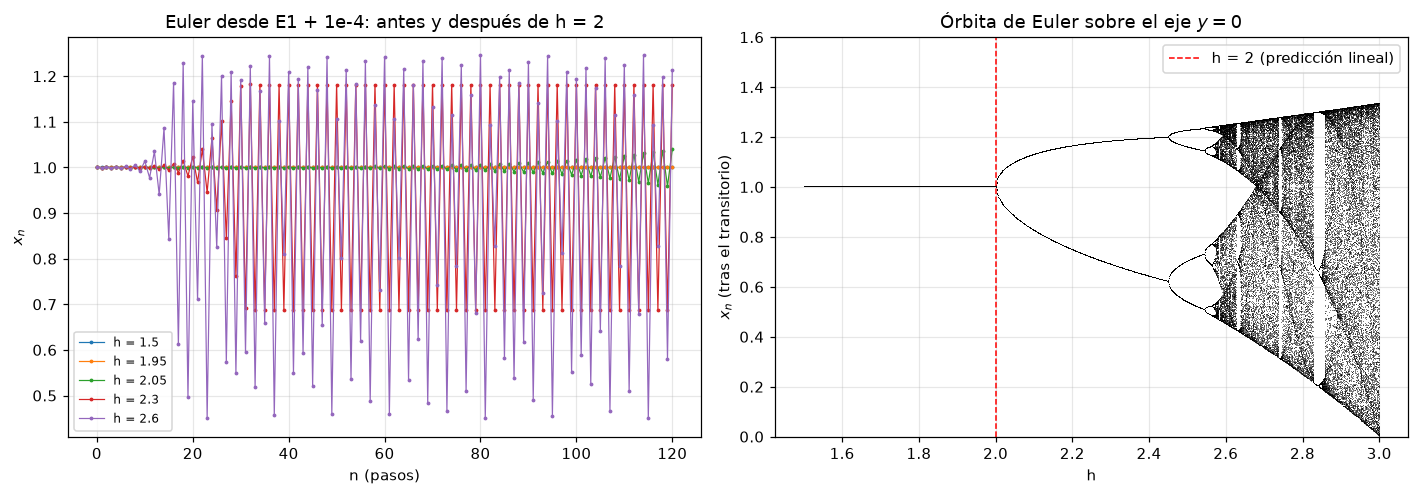

In [18]:
# Task 2.4d — Mayor h con el que Euler todavía converge a E1, por bisección
from math import hypot, isfinite


def euler_converge(h, z0, tol=1e-8, nmax=200_000):
    """True si Euler llega a ||z - E1|| < tol en a lo sumo nmax pasos (bucle escalar rápido)."""
    x, y = z0
    for _ in range(nmax):
        x, y = x + h * r1 * x * (1 - x - a12 * y), y + h * r2 * y * (1 - y - a21 * x)
        d = hypot(x - 1.0, y)
        if d < tol:
            return True
        if not isfinite(d) or d > 1e6:
            return False
    return False


def biseccion_h(z0, lo=0.5, hi=4.0, it=30):
    assert euler_converge(lo, z0) and not euler_converge(hi, z0)
    for _ in range(it):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if euler_converge(mid, z0) else (lo, mid)
    return lo


v_l = V1[:, 1] / np.linalg.norm(V1[:, 1])
z_cerca = zs + 1e-4 * np.array([np.cos(np.pi/4), np.sin(np.pi/4)])
h_num = biseccion_h(z_cerca)
print(f"Desde E1 + 1e-4(cos45°, sin45°): h_max numérico = {h_num:.6f}   (teórico {h_teo})")
print(f"Error relativo = {abs(h_num - h_teo)/h_teo:.2e}")
for k, z0_ in P.items():
    print(f"Desde {k} {z0_}: h_max numérico = {biseccion_h(z0_):.6f}")

# ¿Qué pasa justo después de h = 2? Iteramos Euler y miramos el estado final
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for h_ in [1.5, 1.95, 2.05, 2.3, 2.6]:
    _, Ze = euler(f, z_cerca, h_, 120 * h_)
    axs[0].plot(np.arange(len(Ze)), Ze[:, 0], ".-", ms=3, lw=0.8, label=f"h = {h_}")
    print(f"h = {h_}: últimos x_n = {Ze[-4:, 0].round(5)}, y_n final = {Ze[-1, 1]:.1e}")
axs[0].set(xlabel="n (pasos)", ylabel=r"$x_n$", title="Euler desde E1 + 1e-4: antes y después de h = 2")
axs[0].legend(fontsize=8)
# Diagrama de órbita del mapa de Euler sobre el eje y = 0: x_{n+1} = x_n + h x_n (1 - x_n)
H = np.linspace(1.5, 3.0, 1200)
xh = np.full_like(H, 0.5)
for _ in range(1000):
    xh = xh + H * r1 * xh * (1 - xh)
for _ in range(150):
    xh = xh + H * r1 * xh * (1 - xh)
    axs[1].plot(H, xh, ",k", alpha=0.5)
axs[1].axvline(2, color="r", ls="--", lw=1, label="h = 2 (predicción lineal)")
axs[1].set(xlabel="h", ylabel=r"$x_n$ (tras el transitorio)", ylim=(0, 1.6),
           title=r"Órbita de Euler sobre el eje $y=0$")
axs[1].legend()
plt.tight_layout()
plt.show()

In [19]:
# Task 2.5a — Campaña puntual: P2 -> (0.8, 0.3 + Delta). ¿Algún Delta cambia el destino?
def destino(z0_, T=400.0, h=0.05):
    """Equilibrio al que llega z0_. Con y0 grande el sistema es rígido (y' ~ -r2 y^2), así que
    los primeros 2 u.t. se integran con paso h0 = h / max(1, y0) para que RK4 sea estable."""
    h0 = h / max(1.0, z0_[1])
    _, Z1 = rk4(f, z0_, h0, 2.0)
    _, Z = rk4(f, Z1[-1], h, T - 2.0)
    d = [np.linalg.norm(Z[-1] - np.array(EQ[k])) for k in factibles]
    return list(factibles)[int(np.argmin(d))], Z[-1]

deltas = [0, 0.1, 0.5, 1, 2, 5, 10, 50, 100, 1000]
for D in deltas:
    k, zf = destino((0.8, 0.3 + D))
    print(f"Delta = {D:7.1f}: z0 = (0.8, {0.3 + D:7.1f}) -> {k}  z(400) = ({zf[0]:.6f}, {zf[1]:.1e})")

# La bisección necesita un intervalo [Delta_lo, Delta_hi] con destinos distintos
k_lo, _ = destino((0.8, 0.3))
k_hi, _ = destino((0.8, 0.3 + 1000))
print(f"\ndestino(Delta=0) = {k_lo}, destino(Delta=1000) = {k_hi} -> "
      + ("hay cambio de destino" if k_lo != k_hi else
         "el destino no cambia: no hay intervalo para iniciar la bisección"))

Delta =     0.0: z0 = (0.8,     0.3) -> E1  z(400) = (1.000000, 1.2e-44)
Delta =     0.1: z0 = (0.8,     0.4) -> E1  z(400) = (1.000000, 1.6e-44)
Delta =     0.5: z0 = (0.8,     0.8) -> E1  z(400) = (1.000000, 3.0e-44)


Delta =     1.0: z0 = (0.8,     1.3) -> E1  z(400) = (1.000000, 4.6e-44)
Delta =     2.0: z0 = (0.8,     2.3) -> E1  z(400) = (1.000000, 7.4e-44)
Delta =     5.0: z0 = (0.8,     5.3) -> E1  z(400) = (1.000000, 1.4e-43)


Delta =    10.0: z0 = (0.8,    10.3) -> E1  z(400) = (1.000000, 2.3e-43)
Delta =    50.0: z0 = (0.8,    50.3) -> E1  z(400) = (1.000000, 7.5e-43)
Delta =   100.0: z0 = (0.8,   100.3) -> E1  z(400) = (1.000000, 1.3e-42)


Delta =  1000.0: z0 = (0.8,  1000.3) -> E1  z(400) = (1.000000, 7.0e-42)



destino(Delta=0) = E1, destino(Delta=1000) = E1 -> el destino no cambia: no hay intervalo para iniciar la bisección


lambda_y(E1) = r2(1 - a21) = 0  ->  a21_c = 1
a21 = 0.9: z(400) = (0.8696, 0.2174); interior = (0.8696, 0.2174) factible


a21 = 1.1: z(400) = (1.0000, 0.0000); interior = (1.1765, -0.2941) no factible
a21 = 0.99: z(400) = (0.9830, 0.0283); interior = (0.9852, 0.0246) factible
a21 = 1.01: z(400) = (0.9978, 0.0037); interior = (1.0152, -0.0254) no factible


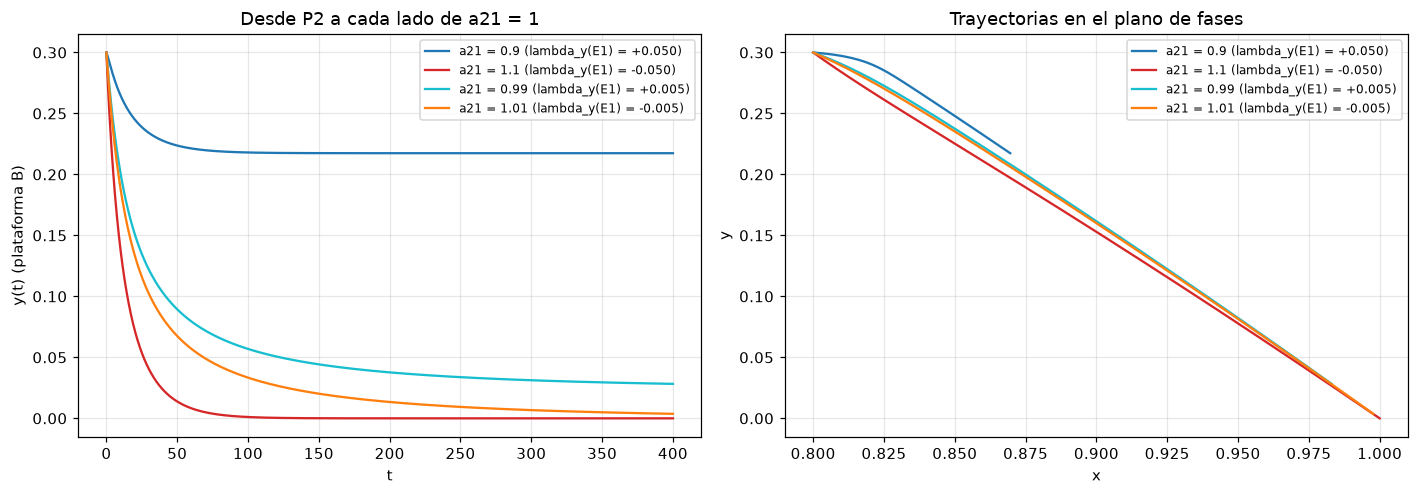

In [20]:
# Task 2.5b — Valor crítico de a21 (rivalidad que sufre B): lambda_y(E1) = r2 (1 - a21) = 0
print("lambda_y(E1) = r2(1 - a21) = 0  ->  a21_c = 1")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for a21_, c in [(0.9, "tab:blue"), (1.1, "tab:red"), (0.99, "tab:cyan"), (1.01, "tab:orange")]:
    f_ = make_f(a21=a21_)
    t_, Z = rk4(f_, P["P2"], 0.05, 400)
    lam_y = r2 * (1 - a21_)
    xi, yi = interior(a12, a21_)
    lbl = f"a21 = {a21_} (lambda_y(E1) = {lam_y:+.3f})"
    axs[0].plot(t_, Z[:, 1], color=c, label=lbl)
    axs[1].plot(Z[:, 0], Z[:, 1], color=c, label=lbl)
    print(f"a21 = {a21_}: z(400) = ({Z[-1,0]:.4f}, {Z[-1,1]:.4f}); "
          f"interior = ({xi:.4f}, {yi:.4f}) {'factible' if yi > 0 else 'no factible'}")
axs[0].set(xlabel="t", ylabel="y(t) (plataforma B)", title="Desde P2 a cada lado de a21 = 1")
axs[1].set(xlabel="x", ylabel="y", title="Trayectorias en el plano de fases")
for a in axs:
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

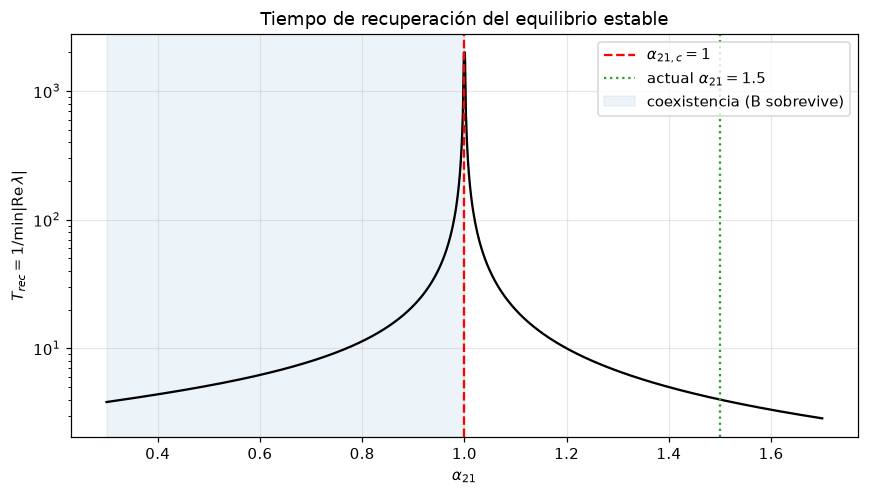

  a21         equilibrio      y*  min|Re l|    T_rec
 0.50 (0.571, 0.714)   0.714     0.1946      5.1
 0.60 (0.625, 0.625)   0.625     0.1610      6.2
 0.70 (0.690, 0.517)   0.517     0.1258      8.0
 0.80 (0.769, 0.385)   0.385     0.0881     11.4
 0.90 (0.870, 0.217)   0.217     0.0467     21.4
 0.95 (0.930, 0.116)   0.116     0.0241     41.5
 0.99 (0.985, 0.025)   0.025     0.0050    201.5
 1.01 (1.000, 0.000)   0.000     0.0050    200.0
 1.10 (1.000, 0.000)   0.000     0.0500     20.0
 1.50 (1.000, 0.000)   0.000     0.2500      4.0


In [21]:
# Task 2.5c — Tiempo de recuperación del equilibrio estable en función de a21
def eq_estable(a21_):
    """Equilibrio estable para a12 = 0.6: interior si a21 < 1, si no E1 = (1, 0)."""
    xi, yi = interior(a12, a21_)
    return (xi, yi) if (a21_ < 1 and yi > 0) else (1.0, 0.0)

A = np.linspace(0.3, 1.7, 700)
s_min = np.array([np.min(np.abs(np.linalg.eigvals(jac(*eq_estable(a), a21=a)).real)) for a in A])
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(A, 1 / s_min, color="k")
ax.axvline(1, color="r", ls="--", label=r"$\alpha_{21,c} = 1$")
ax.axvline(a21, color="tab:green", ls=":", label=r"actual $\alpha_{21} = 1.5$")
ax.axvspan(0.3, 1, color="tab:blue", alpha=0.08, label="coexistencia (B sobrevive)")
ax.set(yscale="log", xlabel=r"$\alpha_{21}$", ylabel=r"$T_{rec} = 1/\min|\mathrm{Re}\,\lambda|$",
       title="Tiempo de recuperación del equilibrio estable")
ax.legend()
plt.tight_layout()
plt.show()

print(f"{'a21':>5} {'equilibrio':>18} {'y*':>7} {'min|Re l|':>10} {'T_rec':>8}")
for a in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1.01, 1.1, 1.5]:
    ze = eq_estable(a)
    s = np.min(np.abs(np.linalg.eigvals(jac(*ze, a21=a)).real))
    print(f"{a:5.2f} ({ze[0]:.3f}, {ze[1]:.3f}) {ze[1]:7.3f} {s:10.4f} {1/s:8.1f}")